# Install & imports

In [1]:
!pip install -q torch-geometric

import torch
import torch.nn as nn
import torch.nn.functional as torch_F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 74.8 MB/s eta 0:00:00
Device: cuda


# Reconnect paths, load test data + trained models

In [2]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/PD_EEG_Thesis_Features_v2')
SPLIT_DIR    = PROJECT_ROOT / 'data' / 'split'
RESULTS_DIR  = PROJECT_ROOT / 'results'
FIG_DIR      = PROJECT_ROOT / 'figures'

test_data = np.load(str(SPLIT_DIR / 'test_data.npz'))
nf_test, adj_test, y_test = test_data['node_features'], test_data['adj'], test_data['y']
print(f'Test set: {nf_test.shape}   PD: {int(y_test.sum())}   Control: {int((y_test==0).sum())}')

Mounted at /content/drive
Test set: (627, 6, 60, 17)   PD: 417   Control: 210


# Model definitions (identical to Notebook 7)

In [3]:
N_TIMESTEPS, N_FEATURES = 6, 17
HIDDEN_DIM, N_HEADS, DROPOUT = 48, 4, 0.25

class EEGFeatureGraphDataset(Dataset):
    def __init__(self, nf, adj, y):
        self.nf, self.adj, self.y = nf, adj, y
    def __len__(self): return len(self.y)
    def __getitem__(self, idx):
        return (torch.tensor(self.nf[idx], dtype=torch.float32),
                torch.tensor(self.adj[idx], dtype=torch.float32),
                torch.tensor(self.y[idx],  dtype=torch.long))

class AttentionPool(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, 1)
    def forward(self, emb):
        weights = torch_F.softmax(self.attn(emb), dim=1)
        return (weights * emb).sum(dim=1), weights.squeeze(-1)

class TGCN(nn.Module):
    def __init__(self, n_features, hidden_dim, dropout):
        super().__init__()
        self.gc_weight  = nn.Linear(n_features, hidden_dim, bias=False)
        self.pool       = AttentionPool(hidden_dim)
        self.gru        = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=2, dropout=dropout)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, 2)
    def graph_conv(self, x, adj):
        deg = adj.sum(dim=-1, keepdim=True).clamp(min=1)
        x   = torch.bmm(adj / deg, x)
        return torch_F.relu(self.gc_weight(x))
    def forward(self, node_feat, adj):
        B, T, N, Fdim = node_feat.shape
        embs = [self.pool(self.graph_conv(node_feat[:, t], adj))[0] for t in range(T)]
        seq, _ = self.gru(torch.stack(embs, dim=1))
        return self.classifier(self.dropout(seq[:, -1, :]))

class TGIN(nn.Module):
    def __init__(self, n_features, hidden_dim, dropout):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(n_features, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, hidden_dim))
        self.eps  = nn.Parameter(torch.zeros(1))
        self.pool = AttentionPool(hidden_dim)
        self.gru  = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=2, dropout=dropout)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, 2)
    def graph_gin(self, x, adj):
        agg = torch.bmm(adj, x)
        return self.mlp((1 + self.eps) * x + agg)
    def forward(self, node_feat, adj):
        B, T, N, Fdim = node_feat.shape
        embs = [self.pool(self.graph_gin(node_feat[:, t], adj))[0] for t in range(T)]
        seq, _ = self.gru(torch.stack(embs, dim=1))
        return self.classifier(self.dropout(seq[:, -1, :]))

class TGAT(nn.Module):
    def __init__(self, n_features, hidden_dim, n_heads, dropout):
        super().__init__()
        self.n_heads, self.head_dim = n_heads, hidden_dim // n_heads
        self.W_q = nn.Linear(n_features, hidden_dim, bias=False)
        self.W_k = nn.Linear(n_features, hidden_dim, bias=False)
        self.W_v = nn.Linear(n_features, hidden_dim, bias=False)
        self.W_o = nn.Linear(hidden_dim, hidden_dim)
        self.gru        = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=2, dropout=dropout)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, 2)
    def graph_attention(self, x, adj):
        B, N, Fdim = x.shape
        H, D = self.n_heads, self.head_dim
        Q = self.W_q(x).view(B, N, H, D).transpose(1, 2)
        K = self.W_k(x).view(B, N, H, D).transpose(1, 2)
        V = self.W_v(x).view(B, N, H, D).transpose(1, 2)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (D ** 0.5)
        mask   = (adj == 0).unsqueeze(1).expand_as(scores)
        scores = scores.masked_fill(mask, float('-inf'))
        scores = torch.nan_to_num(scores, nan=0.0, neginf=-1e9)
        attn   = torch_F.softmax(scores, dim=-1)
        out    = torch.matmul(attn, V).transpose(1, 2).contiguous().view(B, N, -1)
        return torch_F.relu(self.W_o(out))
    def forward(self, node_feat, adj):
        B, T, N, Fdim = node_feat.shape
        embs = [self.graph_attention(node_feat[:, t], adj).mean(dim=1) for t in range(T)]
        seq, _ = self.gru(torch.stack(embs, dim=1))
        return self.classifier(self.dropout(seq[:, -1, :]))

def build_model(name):
    if name == 'TGCN': return TGCN(N_FEATURES, HIDDEN_DIM, DROPOUT).to(DEVICE)
    if name == 'TGIN': return TGIN(N_FEATURES, HIDDEN_DIM, DROPOUT).to(DEVICE)
    if name == 'TGAT': return TGAT(N_FEATURES, HIDDEN_DIM, N_HEADS, DROPOUT).to(DEVICE)

print('Model definitions loaded.')

Model definitions loaded.


# Load trained checkpoints, run inference on test set

In [4]:
MODEL_NAMES = ['TGCN', 'TGIN', 'TGAT']
test_loader = DataLoader(EEGFeatureGraphDataset(nf_test, adj_test, y_test), batch_size=32)

def evaluate(model, loader):
    model.eval()
    preds, probs, labels = [], [], []
    with torch.no_grad():
        for nf, adj, y in loader:
            nf, adj = nf.to(DEVICE), adj.to(DEVICE)
            logits = model(nf, adj)
            probs.extend(torch_F.softmax(logits, dim=1)[:, 1].cpu().numpy())
            preds.extend(logits.argmax(dim=1).cpu().numpy())
            labels.extend(y.numpy())
    preds, probs, labels = map(np.array, (preds, probs, labels))
    return {
        'accuracy': accuracy_score(labels, preds),
        'balanced_accuracy': balanced_accuracy_score(labels, preds),
        'f1': f1_score(labels, preds, zero_division=0),
        'auc': roc_auc_score(labels, probs)
    }, probs, preds, labels

results = {}
for model_name in MODEL_NAMES:
    model = build_model(model_name)
    state = torch.load(str(RESULTS_DIR / f'{model_name}_trained.pt'), map_location=DEVICE)
    model.load_state_dict(state)
    metrics, probs, preds, labels = evaluate(model, test_loader)
    results[model_name] = {'metrics': metrics, 'probs': probs, 'preds': preds, 'labels': labels}
    print(f'{model_name}: Acc={metrics["accuracy"]:.3f}  BalAcc={metrics["balanced_accuracy"]:.3f}  '
          f'F1={metrics["f1"]:.3f}  AUC={metrics["auc"]:.3f}')

TGCN: Acc=0.730  BalAcc=0.691  F1=0.800  AUC=0.820
TGIN: Acc=0.675  BalAcc=0.640  F1=0.753  AUC=0.758
TGAT: Acc=0.732  BalAcc=0.717  F1=0.791  AUC=0.828


# Confusion matrices

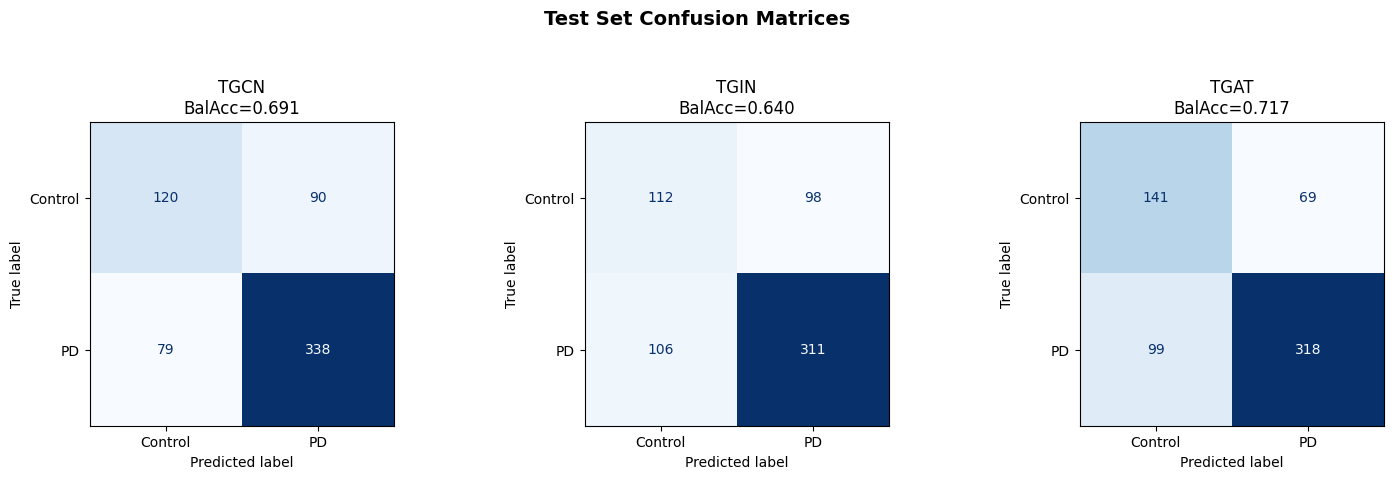

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for i, model_name in enumerate(MODEL_NAMES):
    r = results[model_name]
    cm = confusion_matrix(r['labels'], r['preds'])
    disp = ConfusionMatrixDisplay(cm, display_labels=['Control','PD'])
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False, values_format='d')
    axes[i].set_title(f'{model_name}\nBalAcc={r["metrics"]["balanced_accuracy"]:.3f}')
plt.suptitle('Test Set Confusion Matrices', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.savefig(str(FIG_DIR / 'test_confusion_matrices.png'), dpi=130, bbox_inches='tight')
plt.show()

# ROC-AUC curves

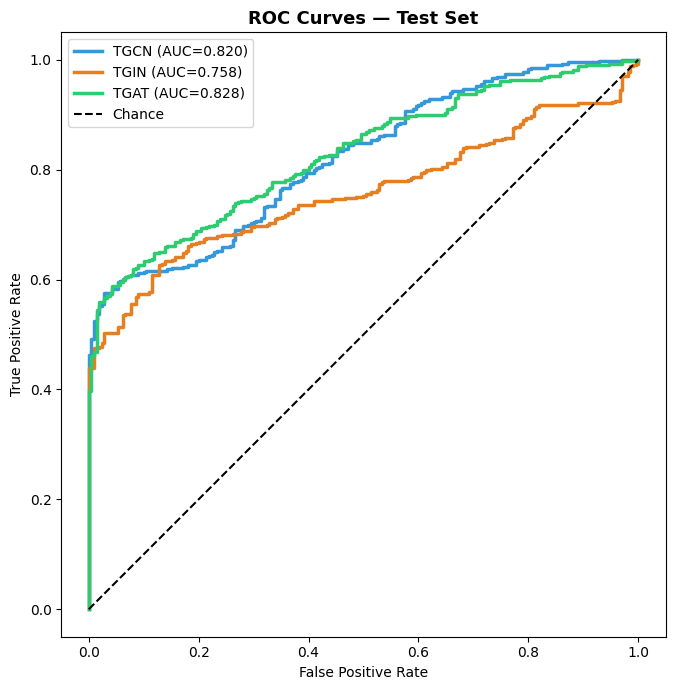

In [ ]:
fig, ax = plt.subplots(figsize=(7,7))
colors = {'TGCN':'#3498db','TGIN':'#e67e22','TGAT':'#2ecc71'}
for model_name in MODEL_NAMES:
    r = results[model_name]
    fpr, tpr, _ = roc_curve(r['labels'], r['probs'])
    ax.plot(fpr, tpr, label=f'{model_name} (AUC={r["metrics"]["auc"]:.3f})', color=colors[model_name], linewidth=2.5)
ax.plot([0,1],[0,1],'k--', label='Chance')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — Test Set', fontsize=13, fontweight='bold')
ax.legend(); ax.set_aspect('equal')
plt.tight_layout()
plt.savefig(str(FIG_DIR / 'test_roc_curves.png'), dpi=130, bbox_inches='tight')
plt.show()

# Final results table

In [ ]:
results_df = pd.DataFrame([
    {'model': m, **results[m]['metrics']} for m in MODEL_NAMES
])
results_df.to_csv(str(RESULTS_DIR / 'test_results_final.csv'), index=False)
print('=== FINAL TEST RESULTS ===\n')
print(results_df.to_string(index=False))

=== FINAL TEST RESULTS ===

model  accuracy  balanced_accuracy       f1      auc
 TGCN  0.730463           0.690990 0.800000 0.820087
 TGIN  0.674641           0.639568 0.753027 0.758490
 TGAT  0.732057           0.717009 0.791045 0.828080


# Per-class precision/recall breakdown

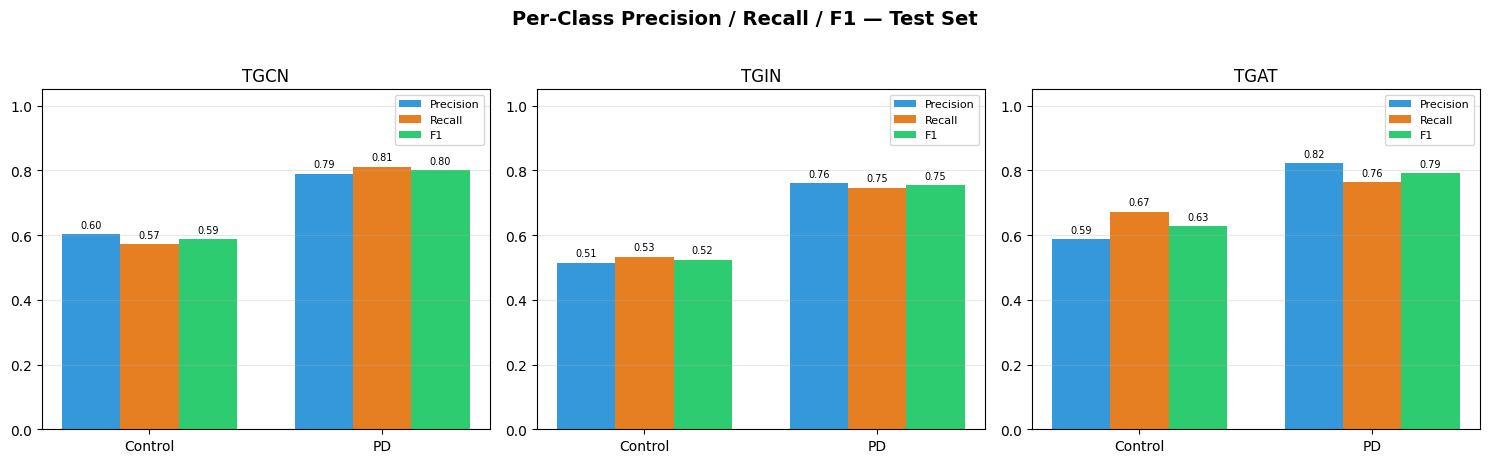

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for i, model_name in enumerate(MODEL_NAMES):
    r = results[model_name]
    precision, recall, f1_per_class, support = precision_recall_fscore_support(
        r['labels'], r['preds'], labels=[0, 1], zero_division=0)

    x = np.arange(2)
    width = 0.25
    axes[i].bar(x - width, precision, width, label='Precision', color='#3498db')
    axes[i].bar(x, recall, width, label='Recall', color='#e67e22')
    axes[i].bar(x + width, f1_per_class, width, label='F1', color='#2ecc71')

    axes[i].set_xticks(x)
    axes[i].set_xticklabels(['Control', 'PD'])
    axes[i].set_ylim(0, 1.05)
    axes[i].set_title(model_name)
    axes[i].legend(fontsize=8)
    axes[i].grid(axis='y', alpha=0.3)

    for j, vals in enumerate([precision, recall, f1_per_class]):
        for k, v in enumerate(vals):
            axes[i].text(x[k] + (j-1)*width, v + 0.02, f'{v:.2f}', ha='center', fontsize=7)

plt.suptitle('Per-Class Precision / Recall / F1 — Test Set', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(str(FIG_DIR / 'test_per_class_breakdown.png'), dpi=130, bbox_inches='tight')
plt.show()

# Combined summary panel

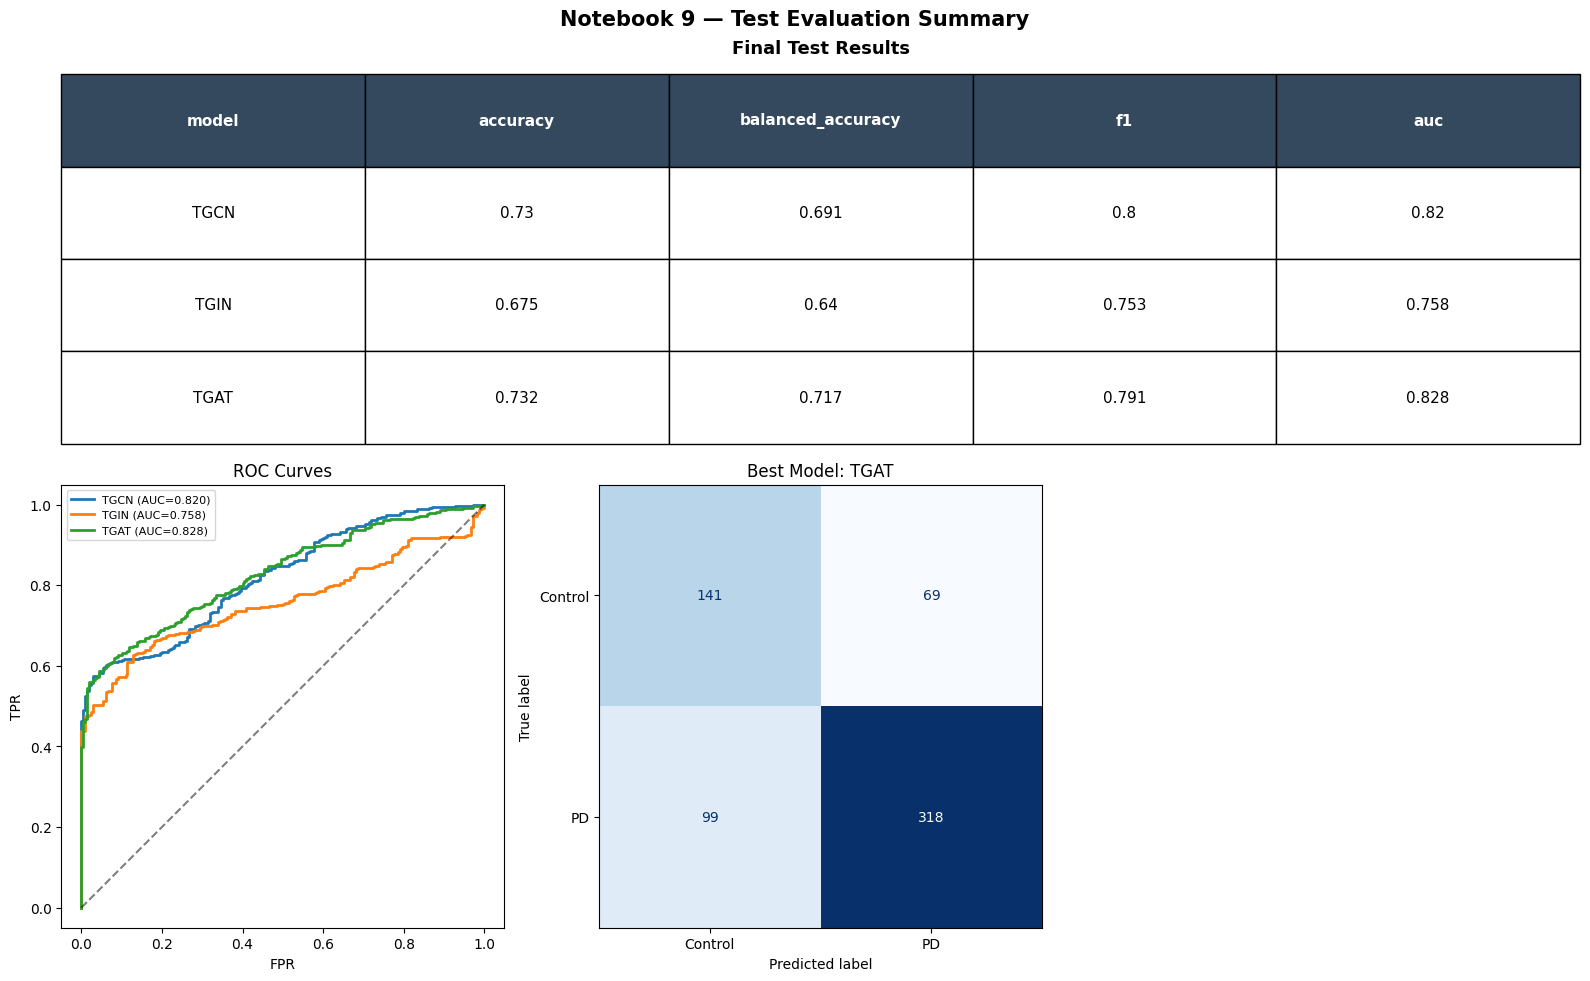

Best model by balanced accuracy: TGAT


In [ ]:
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.3])

# Top: metrics table
ax_table = fig.add_subplot(gs[0, :])
ax_table.axis('off')
table_data = results_df.round(3).values
table = ax_table.table(cellText=table_data, colLabels=results_df.columns,
                       cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2)
for j in range(len(results_df.columns)):
    table[(0, j)].set_facecolor('#34495e')
    table[(0, j)].set_text_props(color='white', fontweight='bold')
ax_table.set_title('Final Test Results', fontsize=13, fontweight='bold', pad=15)

# Bottom-left: ROC
ax_roc = fig.add_subplot(gs[1, 0])
for model_name in MODEL_NAMES:
    r = results[model_name]
    fpr, tpr, _ = roc_curve(r['labels'], r['probs'])
    ax_roc.plot(fpr, tpr, label=f'{model_name} (AUC={r["metrics"]["auc"]:.3f})', linewidth=2)
ax_roc.plot([0,1],[0,1],'k--', alpha=0.5)
ax_roc.set_xlabel('FPR'); ax_roc.set_ylabel('TPR'); ax_roc.set_title('ROC Curves')
ax_roc.legend(fontsize=8); ax_roc.set_aspect('equal')

# Bottom-middle/right: best model's confusion matrix
best_model = results_df.loc[results_df['balanced_accuracy'].idxmax(), 'model']
ax_cm = fig.add_subplot(gs[1, 1])
cm = confusion_matrix(results[best_model]['labels'], results[best_model]['preds'])
ConfusionMatrixDisplay(cm, display_labels=['Control','PD']).plot(ax=ax_cm, cmap='Blues', colorbar=False)
ax_cm.set_title(f'Best Model: {best_model}')

fig.delaxes(fig.add_subplot(gs[1, 2]))   # spare panel, kept blank intentionally

plt.suptitle('Notebook 9 — Test Evaluation Summary', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig(str(FIG_DIR / 'test_summary_panel.png'), dpi=140, bbox_inches='tight')
plt.show()

print(f'Best model by balanced accuracy: {best_model}')

# Extended confusion-matrix-derived metrics (Sensitivity, Specificity, NPV, FPR, FNR, FDR, FOR, MCC, Gini, Log Loss, Cohen's Kappa, F2)

In [ ]:
from sklearn.metrics import matthews_corrcoef, log_loss, cohen_kappa_score, fbeta_score

extended_metrics = []
for model_name in MODEL_NAMES:
    r = results[model_name]
    cm = confusion_matrix(r['labels'], r['preds'])
    tn, fp, fn, tp = cm.ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    npv         = tn / (tn + fn) if (tn + fn) > 0 else 0
    fpr         = fp / (tn + fp) if (tn + fp) > 0 else 0
    fnr         = fn / (tp + fn) if (tp + fn) > 0 else 0
    fdr         = fp / (tp + fp) if (tp + fp) > 0 else 0
    fmr         = fn / (tn + fn) if (tn + fn) > 0 else 0
    mcc         = matthews_corrcoef(r['labels'], r['preds'])
    gini        = 2 * r['metrics']['auc'] - 1
    logloss     = log_loss(r['labels'], np.column_stack([1 - r['probs'], r['probs']]))
    kappa       = cohen_kappa_score(r['labels'], r['preds'])
    f2          = fbeta_score(r['labels'], r['preds'], beta=2, zero_division=0)

    extended_metrics.append({
        'Model': model_name,
        'Sensitivity (TPR)': sensitivity, 'Specificity (TNR)': specificity,
        'NPV': npv, 'FPR': fpr, 'FNR': fnr, 'FDR': fdr, 'FOR': fmr,
        'MCC': mcc, 'Gini': gini, 'Log Loss': logloss,
        "Cohen's Kappa": kappa, 'F2 Score': f2,
    })

extended_df = pd.DataFrame(extended_metrics)
extended_df.to_csv(str(RESULTS_DIR / 'extended_metrics.csv'), index=False)
print('=== Extended Metrics (including Cohen\'s Kappa, F2) ===\n')
print(extended_df.round(3).to_string(index=False))

=== Extended Metrics (including Cohen's Kappa, F2) ===

Model  Sensitivity (TPR)  Specificity (TNR)   NPV   FPR   FNR   FDR   FOR   MCC  Gini  Log Loss  Cohen's Kappa  F2 Score
 TGCN              0.811              0.571 0.603 0.429 0.189 0.210 0.397 0.387 0.640     0.482          0.387     0.806
 TGIN              0.746              0.533 0.514 0.467 0.254 0.240 0.486 0.277 0.517     0.668          0.277     0.749
 TGAT              0.763              0.671 0.588 0.329 0.237 0.178 0.412 0.421 0.656     0.470          0.419     0.774


# Precision-Recall curves

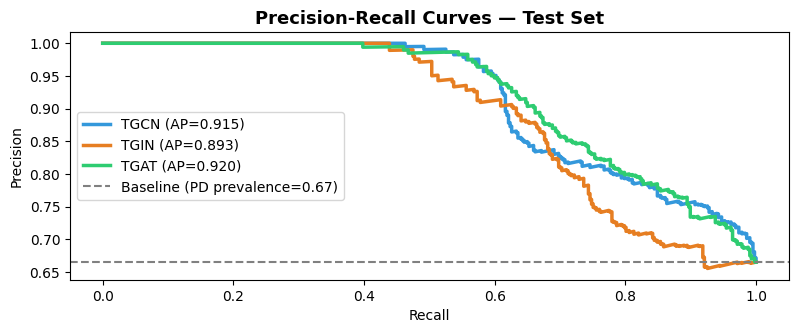

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

fig, ax = plt.subplots(figsize=(8, 8))
for model_name in MODEL_NAMES:
    r = results[model_name]
    prec, rec, _ = precision_recall_curve(r['labels'], r['probs'])
    ap = average_precision_score(r['labels'], r['probs'])
    ax.plot(rec, prec, label=f'{model_name} (AP={ap:.3f})', color=colors[model_name], linewidth=2.5)

baseline = results[MODEL_NAMES[0]]['labels'].mean()
ax.axhline(baseline, color='gray', linestyle='--', label=f'Baseline (PD prevalence={baseline:.2f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curves — Test Set', fontsize=13, fontweight='bold')
ax.legend(); ax.set_aspect('equal')
plt.tight_layout()
plt.savefig(str(FIG_DIR / 'test_pr_curves.png'), dpi=130, bbox_inches='tight')
plt.show()

# Calibration curves (reliability diagrams)

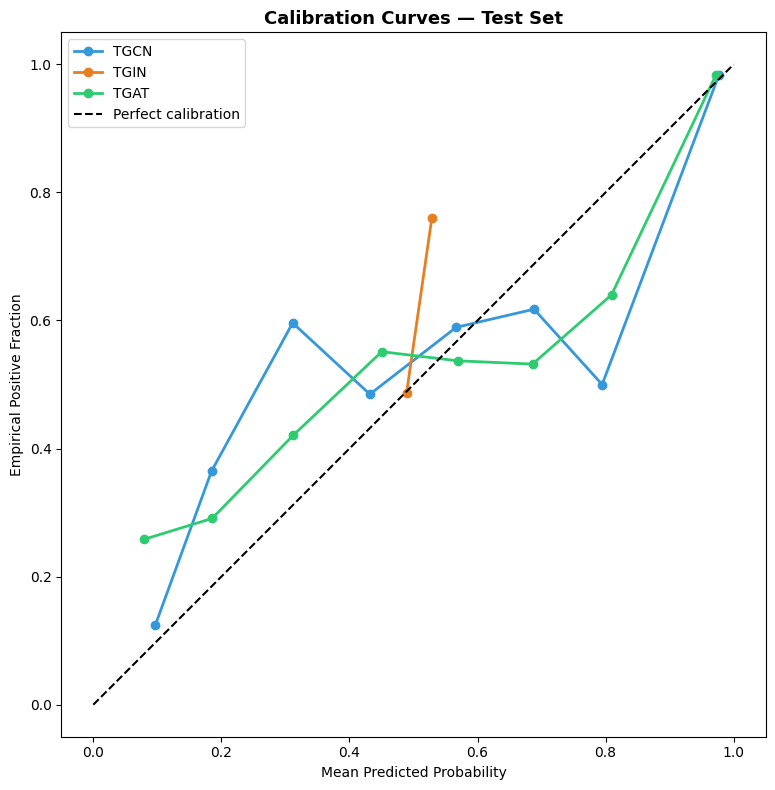

In [ ]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(8, 8))
for model_name in MODEL_NAMES:
    r = results[model_name]
    frac_pos, mean_pred = calibration_curve(r['labels'], r['probs'], n_bins=8)
    ax.plot(mean_pred, frac_pos, marker='o', label=model_name, color=colors[model_name], linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
ax.set_xlabel('Mean Predicted Probability'); ax.set_ylabel('Empirical Positive Fraction')
ax.set_title('Calibration Curves — Test Set', fontsize=13, fontweight='bold')
ax.legend(); ax.set_aspect('equal')
plt.tight_layout()
plt.savefig(str(FIG_DIR / 'test_calibration_curves.png'), dpi=130, bbox_inches='tight')
plt.show()

# Bootstrap 95% CI for best model

In [ ]:
best_model_name = results_df.loc[results_df['balanced_accuracy'].idxmax(), 'model']
r = results[best_model_name]

def bootstrap_ci_test(labels, probs, threshold=0.5, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(labels)
    bal_accs, aucs = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        bl, bp = labels[idx], probs[idx]
        if len(np.unique(bl)) < 2:
            continue
        preds = (bp >= threshold).astype(int)
        bal_accs.append(balanced_accuracy_score(bl, preds))
        aucs.append(roc_auc_score(bl, bp))
    return (np.mean(bal_accs), np.percentile(bal_accs, 2.5), np.percentile(bal_accs, 97.5)), \
           (np.mean(aucs), np.percentile(aucs, 2.5), np.percentile(aucs, 97.5))

(bal_mean, bal_lo, bal_hi), (auc_mean, auc_lo, auc_hi) = bootstrap_ci_test(r['labels'], r['probs'])

print(f'=== Bootstrap 95% CI — {best_model_name} (single test split, n={len(r["labels"])}) ===\n')
print(f'Balanced Accuracy: {bal_mean:.3f}  95% CI [{bal_lo:.3f}, {bal_hi:.3f}]')
print(f'AUC              : {auc_mean:.3f}  95% CI [{auc_lo:.3f}, {auc_hi:.3f}]')
print('\nNote: this CI reflects resampling uncertainty within this single test split only —')
print('it does not replace cross-validation, but it does show how much the point estimate')
print('could plausibly vary given the finite test set size.')

=== Bootstrap 95% CI — TGAT (single test split, n=627) ===

Balanced Accuracy: 0.717  95% CI [0.679, 0.755]
AUC              : 0.828  95% CI [0.797, 0.857]

Note: this CI reflects resampling uncertainty within this single test split only —
it does not replace cross-validation, but it does show how much the point estimate
could plausibly vary given the finite test set size.


# Forest plot: full-montage 95% bootstrap CIs

model metric  point (live) point (ref)         CI (live)          CI (ref)
TGCN  BalAcc         0.691       0.691  [0.652, 0.730]  [0.652, 0.730]
TGCN  AUC            0.820       0.820  [0.788, 0.851]  [0.788, 0.851]
TGIN  BalAcc         0.640       0.640  [0.598, 0.680]  [0.598, 0.680]
TGIN  AUC            0.758       0.758  [0.720, 0.793]  [0.720, 0.793]
TGAT  BalAcc         0.717       0.717  [0.679, 0.755]  [0.679, 0.755]
TGAT  AUC            0.828       0.828  [0.797, 0.857]  [0.797, 0.857]

Largest difference between live values and reference values: 0.0005
OK: checkpoints match the reported numbers.


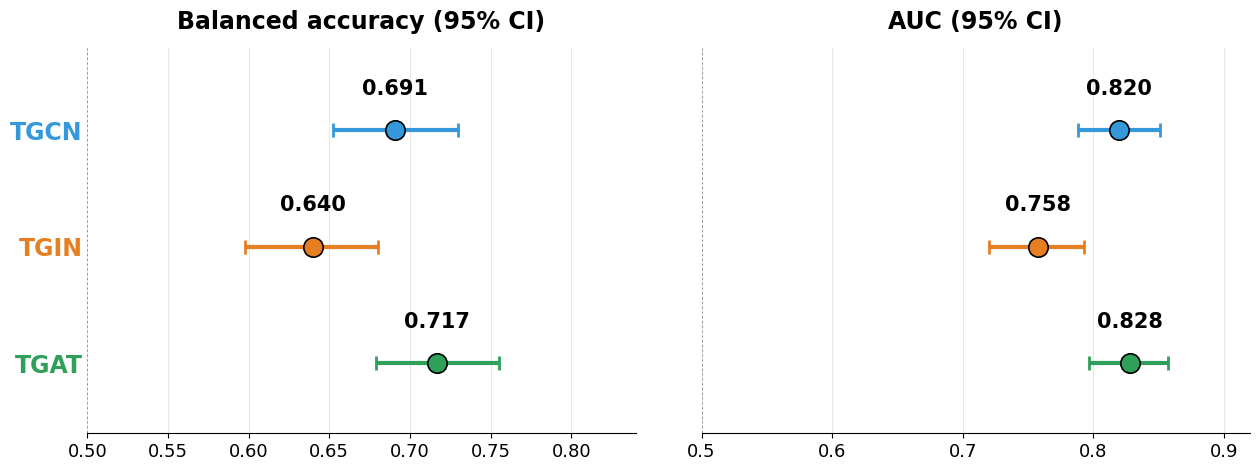

Saved: /content/drive/MyDrive/PD_EEG_Thesis_Features_v2/figures/test_ci_forest_fullmontage.png


In [5]:
# forest plot of full-montage balanced accuracy / AUC with 95% bootstrap CIs.
# Inference-only: reads `results` built in the "Load trained checkpoints" cell. Trains nothing, writes nothing to results/.
assert 'results' in globals() and 'MODEL_NAMES' in globals(), 'Run the cells that build `results` first.'

# ---- reference values (thesis_state_v2.md / Table 4.3): point, CI_low, CI_high ----
BALACC = {'TGCN': (0.691, 0.652, 0.730), 'TGIN': (0.640, 0.598, 0.680), 'TGAT': (0.717, 0.679, 0.755)}
AUC    = {'TGCN': (0.820, 0.788, 0.851), 'TGIN': (0.758, 0.720, 0.793), 'TGAT': (0.828, 0.797, 0.857)}
CI_COLORS = {'TGCN': '#3498db', 'TGIN': '#e67e22', 'TGAT': '#2ea05a'}

# ---- live check against the loaded checkpoints (same method as the bootstrap cell: 2,000 resamples, seed 42) ----
def _boot(labels, probs, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed); n = len(labels); ba, au = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n); bl, bp = labels[idx], probs[idx]
        if len(np.unique(bl)) < 2: continue
        ba.append(balanced_accuracy_score(bl, (bp >= 0.5).astype(int))); au.append(roc_auc_score(bl, bp))
    return np.percentile(ba, [2.5, 97.5]), np.percentile(au, [2.5, 97.5])

print(f'{"model":5s} {"metric":7s} {"point (live)":>12s} {"point (ref)":>11s}  {"CI (live)":>16s}  {"CI (ref)":>16s}')
worst = 0.0
for m in MODEL_NAMES:
    r = results[m]
    (b_lo, b_hi), (a_lo, a_hi) = _boot(r['labels'], r['probs'])
    for name, ref, pt, lo, hi in (('BalAcc', BALACC[m], r['metrics']['balanced_accuracy'], b_lo, b_hi),
                                  ('AUC',    AUC[m],    r['metrics']['auc'],               a_lo, a_hi)):
        worst = max(worst, abs(pt - ref[0]), abs(lo - ref[1]), abs(hi - ref[2]))
        print(f'{m:5s} {name:7s} {pt:12.3f} {ref[0]:11.3f}  [{lo:.3f}, {hi:.3f}]  [{ref[1]:.3f}, {ref[2]:.3f}]')
print(f'\nLargest difference between live values and reference values: {worst:.4f}')
print('OK: checkpoints match the reported numbers.' if worst <= 0.0015 else
      'CHECK: live values differ from the report. Make sure results/ holds the original checkpoints before using this figure.')

# ---- figure (plots the REPORT values so it matches Tables 4.1 and 4.3) ----
def _forest(ax, data, title, xlim, xticks):
    ypos = {m: len(MODEL_NAMES) - 1 - i for i, m in enumerate(MODEL_NAMES)}
    for m in MODEL_NAMES:
        p, lo, hi = data[m]
        ax.errorbar(p, ypos[m], xerr=[[p - lo], [hi - p]], fmt='none', ecolor=CI_COLORS[m],
                    elinewidth=3, capsize=5, capthick=2)
        ax.plot(p, ypos[m], 'o', ms=14, mfc=CI_COLORS[m], mec='black', mew=1.2, zorder=3)
        ax.text(p, ypos[m] + 0.27, f'{p:.3f}', ha='center', va='bottom', fontsize=15, fontweight='bold')
    ax.axvline(xlim[0], color='gray', ls=':', lw=1.3)
    ax.set_xlim(*xlim); ax.set_xticks(xticks); ax.set_ylim(-0.6, len(MODEL_NAMES) - 0.3)
    ax.grid(axis='x', alpha=0.3); ax.set_axisbelow(True)
    ax.set_title(title, fontsize=17, fontweight='bold', pad=14)
    ax.tick_params(axis='x', labelsize=13)
    for s in ('top', 'right', 'left'): ax.spines[s].set_visible(False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'wspace': 0.12})
_forest(ax1, BALACC, 'Balanced accuracy (95% CI)', (0.50, 0.84), np.arange(0.50, 0.801, 0.05))
_forest(ax2, AUC,    'AUC (95% CI)',               (0.50, 0.92), np.arange(0.5, 0.901, 0.1))
ax1.set_yticks([len(MODEL_NAMES) - 1 - i for i in range(len(MODEL_NAMES))])
ax1.set_yticklabels(MODEL_NAMES, fontsize=17, fontweight='bold')
for lbl in ax1.get_yticklabels(): lbl.set_color(CI_COLORS[lbl.get_text()])
ax1.tick_params(axis='y', length=0); ax2.set_yticks([])
plt.savefig(str(FIG_DIR / 'test_ci_forest_fullmontage.png'), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved:', FIG_DIR / 'test_ci_forest_fullmontage.png')

# 3D brain attention graph — all three models

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 76.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


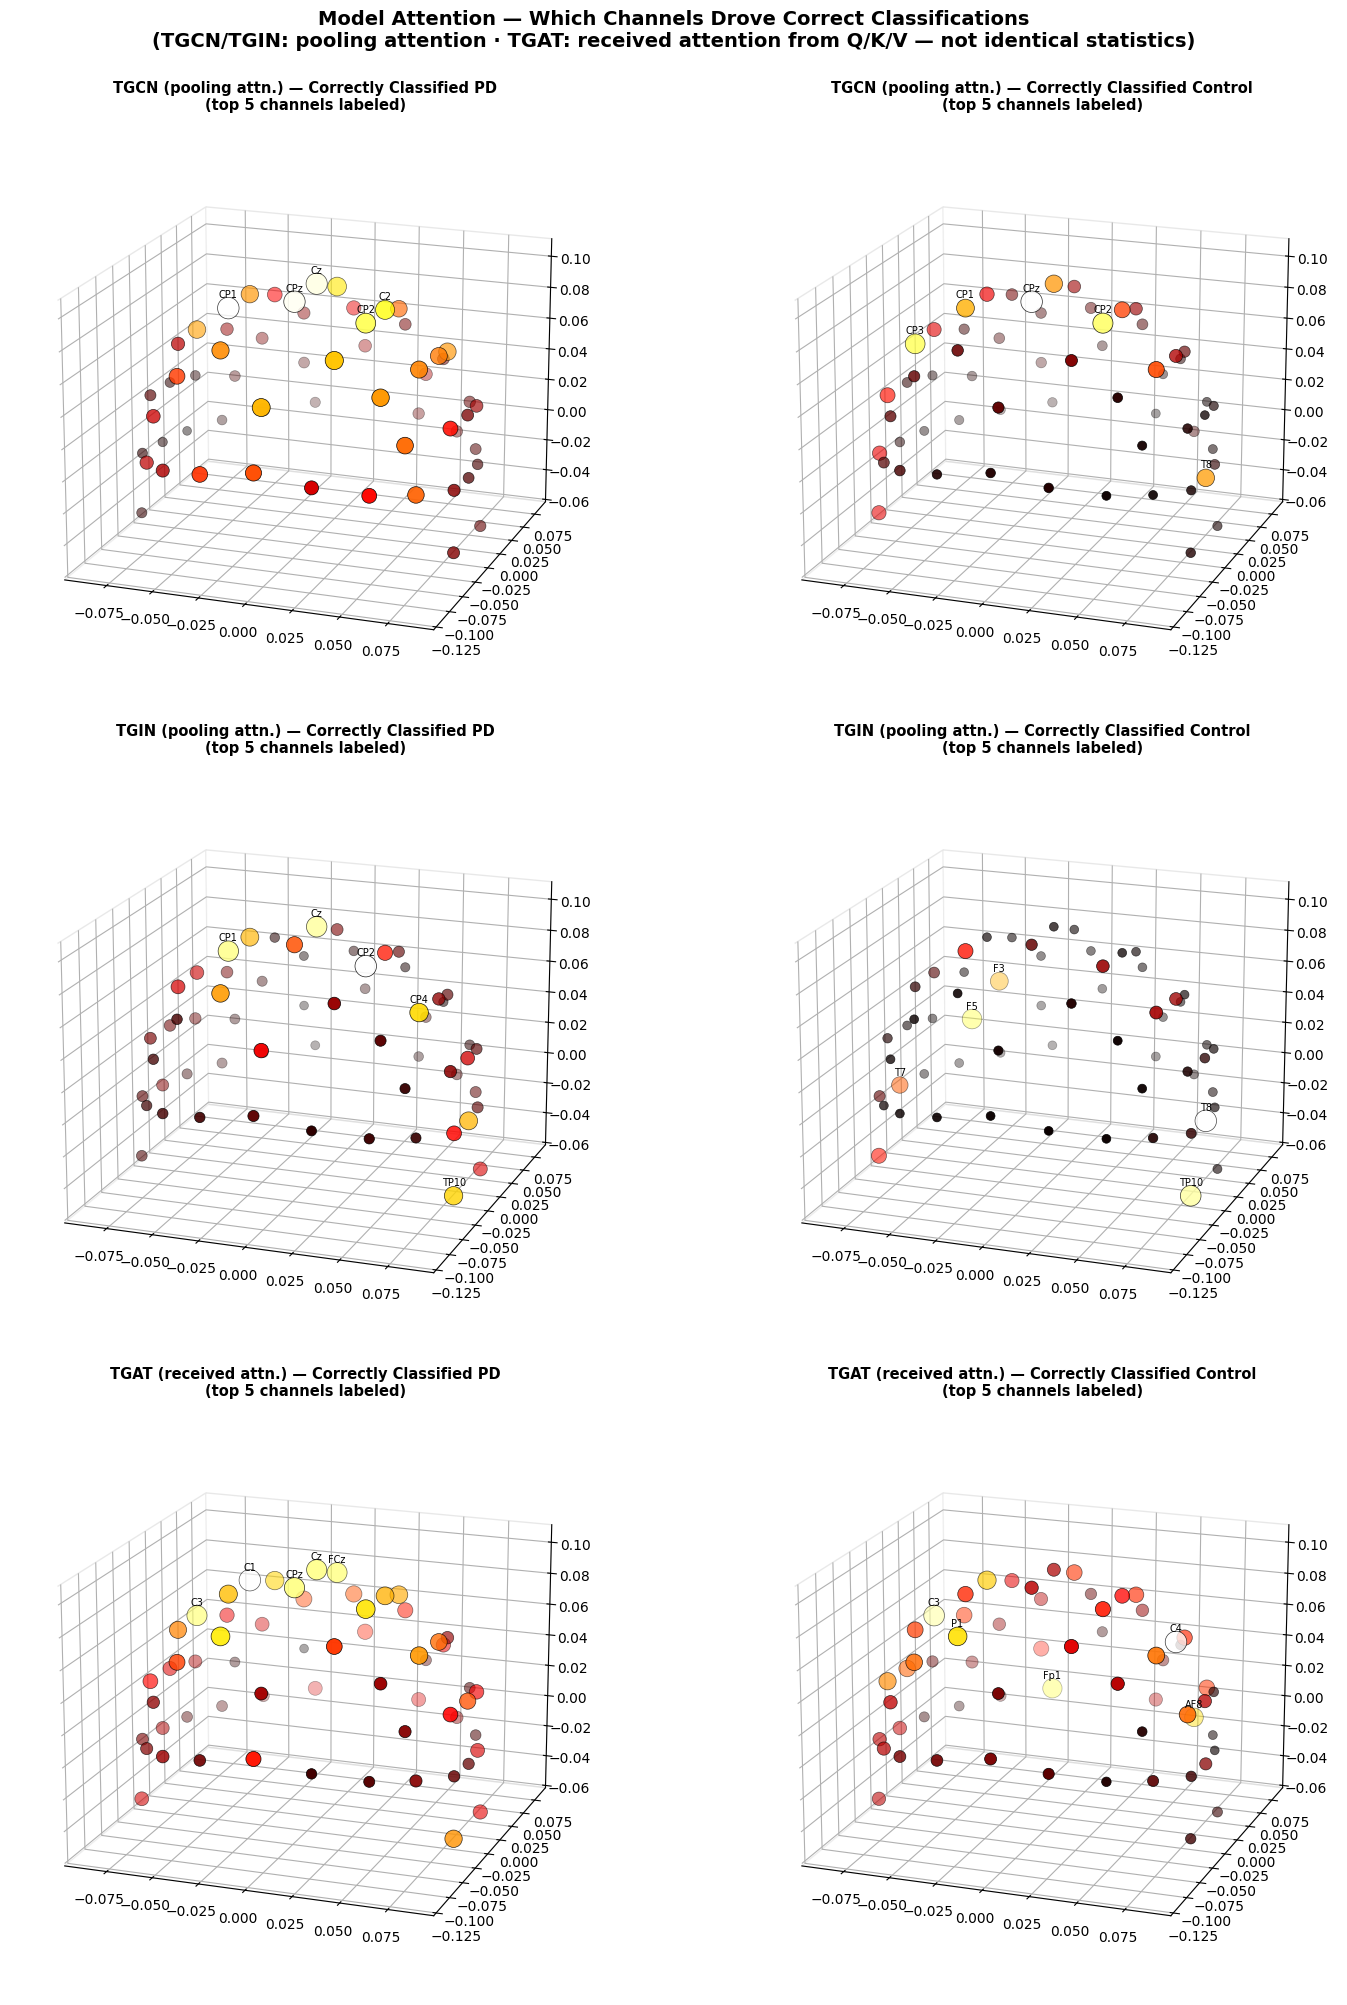

All three models now represented. TGAT uses a derived "received attention" score
from its internal Q/K/V mechanism — conceptually related but not the same computation
as TGCN/TGIN's direct pooling weights. Worth stating this distinction if presenting.


In [ ]:
!pip install -q mne

import gc
import mne
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.patches as mpatches

manifest = pd.read_csv(PROJECT_ROOT / 'manifest.csv')
common_chs = None
for _, row in manifest.iterrows():
    raw_check = mne.io.read_raw_edf(row['edf_path'], preload=False, verbose=False)
    chs = set(raw_check.ch_names)
    common_chs = chs if common_chs is None else common_chs & chs
ref_raw = mne.io.read_raw_edf(manifest.iloc[0]['edf_path'], preload=False, verbose=False)
CHANNEL_NAMES = [ch for ch in ref_raw.ch_names if ch in common_chs]

montage = mne.channels.make_standard_montage('standard_1020')
positions_3d = montage.get_positions()['ch_pos']
coords = np.array([positions_3d[ch] for ch in CHANNEL_NAMES if ch in positions_3d])
matched_channels = [ch for ch in CHANNEL_NAMES if ch in positions_3d]


class AttnTGCN(TGCN):
    def forward(self, node_feat, adj):
        B, T, N, Fdim = node_feat.shape
        embs, attns = [], []
        for t in range(T):
            h = self.graph_conv(node_feat[:, t], adj)
            pooled, w = self.pool(h)
            embs.append(pooled); attns.append(w)
        seq, _ = self.gru(torch.stack(embs, dim=1))
        out = self.classifier(self.dropout(seq[:, -1, :]))
        return out, torch.stack(attns, dim=1)


class AttnTGIN(TGIN):
    def forward(self, node_feat, adj):
        B, T, N, Fdim = node_feat.shape
        embs, attns = [], []
        for t in range(T):
            h = self.graph_gin(node_feat[:, t], adj)
            pooled, w = self.pool(h)
            embs.append(pooled); attns.append(w)
        seq, _ = self.gru(torch.stack(embs, dim=1))
        out = self.classifier(self.dropout(seq[:, -1, :]))
        return out, torch.stack(attns, dim=1)


class AttnTGAT(TGAT):
    """
    TGAT has no separate pooling-attention layer — its attention is the
    internal Q/K/V mechanism between channel pairs. To get a per-channel
    importance score comparable in SHAPE (not identical in meaning) to
    TGCN/TGIN's pooling weights, we compute 'received attention': how much
    each channel is attended TO by other channels, averaged over heads
    and query positions. This is a standard interpretability proxy for
    pairwise attention, not the same statistic as pooling-attention.
    """
    def forward(self, node_feat, adj):
        B, T, N, Fdim = node_feat.shape
        embs, attns = [], []
        H, D = self.n_heads, self.head_dim
        for t in range(T):
            xt = node_feat[:, t]
            Q = self.W_q(xt).view(B, N, H, D).transpose(1, 2)
            K = self.W_k(xt).view(B, N, H, D).transpose(1, 2)
            V = self.W_v(xt).view(B, N, H, D).transpose(1, 2)
            scores = torch.matmul(Q, K.transpose(-2, -1)) / (D ** 0.5)
            mask = (adj == 0).unsqueeze(1).expand_as(scores)
            scores = scores.masked_fill(mask, float('-inf'))
            scores = torch.nan_to_num(scores, nan=0.0, neginf=-1e9)
            attn_weights = torch_F.softmax(scores, dim=-1)   # (B, H, N, N)
            out_t = torch.matmul(attn_weights, V).transpose(1, 2).contiguous().view(B, N, -1)
            h = torch_F.relu(self.W_o(out_t))
            embs.append(h.mean(dim=1))

            received = attn_weights.mean(dim=1).mean(dim=1)   # avg over heads, then query dim -> (B, N)
            attns.append(received)
        seq, _ = self.gru(torch.stack(embs, dim=1))
        out = self.classifier(self.dropout(seq[:, -1, :]))
        return out, torch.stack(attns, dim=1)


def build_attn_model(name):
    if name == 'TGCN': return AttnTGCN(N_FEATURES, HIDDEN_DIM, DROPOUT).to(DEVICE)
    if name == 'TGIN': return AttnTGIN(N_FEATURES, HIDDEN_DIM, DROPOUT).to(DEVICE)
    if name == 'TGAT': return AttnTGAT(N_FEATURES, HIDDEN_DIM, N_HEADS, DROPOUT).to(DEVICE)


attn_test_loader = DataLoader(EEGFeatureGraphDataset(nf_test, adj_test, y_test), batch_size=32)

fig, axes = plt.subplots(3, 2, figsize=(16, 20), subplot_kw={'projection': '3d'})

for row_i, model_name in enumerate(['TGCN', 'TGIN', 'TGAT']):
    model = build_attn_model(model_name)
    state = torch.load(str(RESULTS_DIR / f'{model_name}_trained.pt'), map_location=DEVICE)
    model.load_state_dict(state)
    model.eval()

    correct_pd_attn, correct_hc_attn = [], []
    with torch.no_grad():
        for nf, adj, y in attn_test_loader:
            nf, adj = nf.to(DEVICE), adj.to(DEVICE)
            logits, attn = model(nf, adj)
            preds = logits.argmax(dim=1).cpu().numpy()
            attn_avg = attn.mean(dim=1).cpu().numpy()
            labels_np = y.numpy()
            for i in range(len(preds)):
                if preds[i] == labels_np[i] == 1:
                    correct_pd_attn.append(attn_avg[i])
                elif preds[i] == labels_np[i] == 0:
                    correct_hc_attn.append(attn_avg[i])

    mean_pd_attn = np.mean(correct_pd_attn, axis=0) if correct_pd_attn else np.zeros(len(CHANNEL_NAMES))
    mean_hc_attn = np.mean(correct_hc_attn, axis=0) if correct_hc_attn else np.zeros(len(CHANNEL_NAMES))

    label_suffix = ' (received attn.)' if model_name == 'TGAT' else ' (pooling attn.)'

    for col_i, (attn_vals, cls_label) in enumerate([(mean_pd_attn, 'Correctly Classified PD'),
                                                      (mean_hc_attn, 'Correctly Classified Control')]):
        ax = axes[row_i, col_i]
        matched_attn = np.array([attn_vals[CHANNEL_NAMES.index(ch)] for ch in matched_channels])
        norm_attn = (matched_attn - matched_attn.min()) / (matched_attn.max() - matched_attn.min() + 1e-8)

        xs, ys, zs = coords[:, 0], coords[:, 1], coords[:, 2]
        sizes = 40 + norm_attn * 200
        ax.scatter(xs, ys, zs, c=norm_attn, cmap='hot', s=sizes, edgecolor='black', linewidth=0.5)

        top5_idx = np.argsort(matched_attn)[::-1][:5]
        for idx in top5_idx:
            ax.text(xs[idx], ys[idx], zs[idx] + 0.006, matched_channels[idx], fontsize=7, ha='center')

        for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
            axis.pane.set_facecolor((1, 1, 1, 0))
            axis.pane.set_edgecolor('lightgray')
        ax.view_init(elev=18, azim=-70)
        ax.set_title(f'{model_name}{label_suffix} — {cls_label}\n(top 5 channels labeled)',
                    fontsize=10.5, fontweight='bold')

    del model
    gc.collect(); torch.cuda.empty_cache()

plt.suptitle('Model Attention — Which Channels Drove Correct Classifications\n'
            '(TGCN/TGIN: pooling attention · TGAT: received attention from Q/K/V — not identical statistics)',
            fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(str(FIG_DIR / 'test_3d_attention_graph.png'), dpi=140, bbox_inches='tight')
plt.show()

print('All three models now represented. TGAT uses a derived "received attention" score')
print('from its internal Q/K/V mechanism — conceptually related but not the same computation')
print('as TGCN/TGIN\'s direct pooling weights. Worth stating this distinction if presenting.')

Saved -> /content/drive/MyDrive/PD_EEG_Thesis_Features_v2/figures/test_attention_3d_slide_4x3.png

TGCN  PD      : CP1, CPz, Cz, CP2, C2
TGIN  PD      : CP2, Cz, CP1, CP4, TP10
TGAT  PD      : C1, CPz, Cz, C3, FCz
TGCN  Control : CPz, CP2, CP3, CP1, T8
TGIN  Control : T8, TP10, F5, F3, T7
TGAT  Control : C4, C3, Fp1, P1, AF8


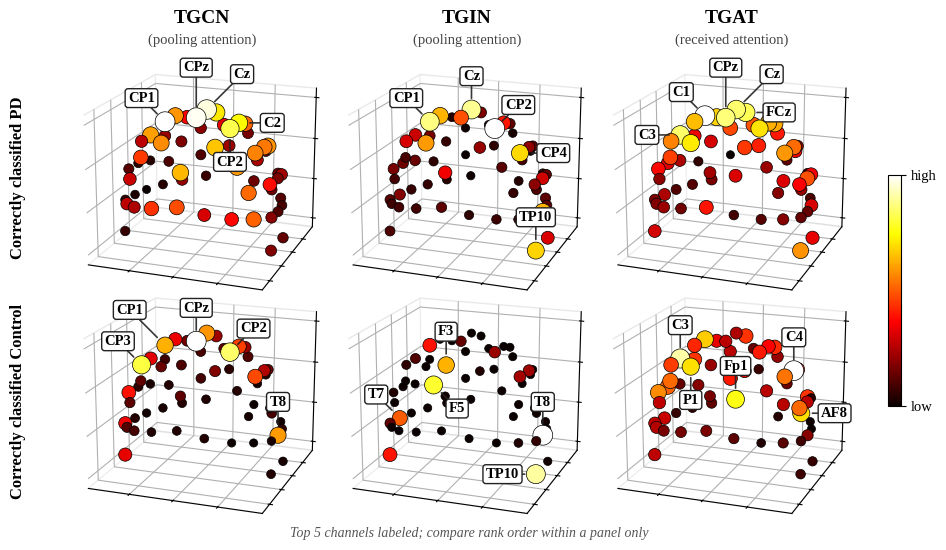

In [ ]:
# 4:3 SLIDE VERSION of the 3D attention figure (9.4 x 5.5 in): your deck is 10 x 7.5 in.
# Run in Notebook 9's session AFTER the top-down attention cell (it needs panel_attn, coords, matched_channels).
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.text import Text
from mpl_toolkits.mplot3d import Axes3D, proj3d

assert 'panel_attn' in globals(), 'Run the top-down attention cell first (it builds panel_attn, coords, matched_channels).'
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Liberation Serif', 'Times New Roman', 'DejaVu Serif']

def label_top_channels(fig, ax, xs, ys, zs, idxs, names, fs, dists=(36, 54, 72, 90, 108)):
    """Callout labels with leader lines for the top channels of one 3D panel.
    Greedy placement; overlap is tested in true page coordinates (anchor + offset), and labels
    also avoid the markers of the other top channels."""
    from matplotlib.transforms import Bbox
    x2, y2, _ = proj3d.proj_transform(xs[idxs], ys[idxs], zs[idxs], ax.get_proj())
    anchors = ax.transData.transform(np.c_[x2, y2])
    renderer = fig.canvas.get_renderer()
    k_px = fig.dpi / 72.0
    pad = 5 * k_px
    placed = [Bbox.from_extents(a[0] - 16 * k_px / 1.0, a[1] - 16 * k_px / 1.0,
                                a[0] + 16 * k_px / 1.0, a[1] + 16 * k_px / 1.0) for a in anchors]
    angles = [90, 135, 45, 180, 0, 225, 315, 270, 60, 120, 30, 150, 240, 300, 210, 330]
    for k, i in enumerate(idxs):
        done = False
        for dist in dists:
            for ang in angles:
                dx, dy = dist * np.cos(np.radians(ang)), dist * np.sin(np.radians(ang))
                ann = ax.annotate(names[i], xy=(x2[k], y2[k]), xycoords='data', xytext=(dx, dy),
                                  textcoords='offset points', ha='center', va='center', fontsize=fs,
                                  fontweight='bold', zorder=20,
                                  bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='#222222', lw=1.0),
                                  arrowprops=dict(arrowstyle='-', lw=1.2, color='#222222', alpha=0.9,
                                                  shrinkA=0, shrinkB=8))
                tb = Text.get_window_extent(ann, renderer)
                cx, cy = anchors[k][0] + dx * k_px, anchors[k][1] + dy * k_px
                box = Bbox.from_extents(cx - tb.width / 2 - pad, cy - tb.height / 2 - pad,
                                        cx + tb.width / 2 + pad, cy + tb.height / 2 + pad)
                own = placed[k]                       # a label may sit near its own marker
                if not any(box.overlaps(p) for j, p in enumerate(placed) if p is not own):
                    placed.append(box); done = True; break
                ann.remove()
            if done: break
        if not done:
            ax.annotate(names[i], xy=(x2[k], y2[k]), xycoords='data', xytext=(dists[0], dists[0]), textcoords='offset points',
                        fontsize=fs, fontweight='bold', zorder=20)

def plot_attention_3d_43(panel_attn, names, coords, models, out_path, topk=5, dpi=300, cmap='hot'):
    """4:3 slide version: 9.4 x 5.5 in, 2 rows (PD / Control) x 3 columns (models), large labels, no tick numbers."""
    xs, ys, zs = coords[:, 0], coords[:, 1], coords[:, 2]
    classes = ['PD', 'Control']
    fig = plt.figure(figsize=(9.4, 5.5))
    fig.subplots_adjust(left=0.075, right=0.92, top=0.865, bottom=0.06, wspace=0.0, hspace=0.02)
    axes, summary = {}, {}
    for ri, cls in enumerate(classes):
        for ci, model in enumerate(models):
            ax = fig.add_subplot(2, 3, ri * 3 + ci + 1, projection='3d')
            axes[(model, cls)] = ax
            v = np.asarray(panel_attn[(model, cls)], dtype=float)
            nv = (v - v.min()) / (v.max() - v.min() + 1e-12)
            ax.scatter(xs, ys, zs, c=nv, cmap=cmap, vmin=0, vmax=1, s=34 + 170 * nv, edgecolor='black', linewidth=0.5, depthshade=False)
            for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
                axis.pane.set_facecolor((1, 1, 1, 0)); axis.pane.set_edgecolor('lightgray')
            ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
            ax.tick_params(length=0)
            ax.set_box_aspect((1, 1, 0.85), zoom=1.30)
            ax.view_init(elev=18, azim=-70)
            summary[(model, cls)] = list(np.argsort(nv)[::-1][:topk])
    fig.canvas.draw()
    for (model, cls), ax in axes.items():
        label_top_channels(fig, ax, xs, ys, zs, np.array(summary[(model, cls)]), names, fs=10.5, dists=(24, 36, 48, 60, 74))
    for ri, cls in enumerate(classes):
        pos = axes[(models[0], cls)].get_position()
        fig.text(0.02, 0.5 * (pos.y0 + pos.y1), f'Correctly classified {cls}', rotation=90, ha='center', va='center', fontsize=12, fontweight='bold')
    cax = fig.add_axes([0.945, 0.25, 0.014, 0.42])
    cb = fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1)), cax=cax)
    cb.set_ticks([0, 1]); cb.set_ticklabels(['low', 'high']); cb.ax.tick_params(labelsize=10.5)
    for ci, model in enumerate(models):
        pos = axes[(model, 'PD')].get_position()
        kind = 'received attention' if model == 'TGAT' else 'pooling attention'
        fig.text(0.5 * (pos.x0 + pos.x1), 0.955, model, ha='center', va='center', fontsize=14, fontweight='bold')
        fig.text(0.5 * (pos.x0 + pos.x1), 0.915, f'({kind})', ha='center', va='center', fontsize=10.5, color='#444444')
    fig.text(0.5, 0.012, 'Top 5 channels labeled; compare rank order within a panel only', ha='center', fontsize=10, color='#555555', style='italic')
    fig.savefig(out_path, dpi=dpi, facecolor='white')
    return {k: [names[i] for i in v] for k, v in summary.items()}

CMAP = 'hot'   # same colormap as the original Figure 4.10
out_path = str(FIG_DIR / 'test_attention_3d_slide_4x3.png')
summary3d = plot_attention_3d_43(panel_attn, matched_channels, coords, ATTN_MODELS, out_path, topk=5, dpi=300, cmap=CMAP)
print(f'Saved -> {out_path}\n')
for (m, c), chs in summary3d.items():
    print(f'{m:5s} {c:8s}: {", ".join(chs)}')

# McNemar's pairwise test

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar
from itertools import combinations

print("=== McNemar's Test — Pairwise Model Comparison ===")
print("(Tests whether two models' errors on the SAME test set differ significantly)\n")

mcnemar_results = []
for model_a, model_b in combinations(MODEL_NAMES, 2):
    preds_a = results[model_a]['preds']
    preds_b = results[model_b]['preds']
    labels  = results[model_a]['labels']   # identical test set/labels across models

    correct_a = (preds_a == labels)
    correct_b = (preds_b == labels)

    # 2x2 contingency table: [both correct, A right/B wrong], [A wrong/B right, both wrong]
    both_correct     = np.sum(correct_a & correct_b)
    a_right_b_wrong  = np.sum(correct_a & ~correct_b)
    a_wrong_b_right  = np.sum(~correct_a & correct_b)
    both_wrong       = np.sum(~correct_a & ~correct_b)

    table = [[both_correct, a_right_b_wrong], [a_wrong_b_right, both_wrong]]
    result = mcnemar(table, exact=False, correction=True)

    significant = "Yes" if result.pvalue < 0.05 else "No"
    print(f'{model_a} vs {model_b}: statistic={result.statistic:.3f}  p-value={result.pvalue:.4f}  '
          f'Significant difference (α=0.05): {significant}')

    mcnemar_results.append({
        'Model A': model_a, 'Model B': model_b,
        'Statistic': result.statistic, 'p-value': result.pvalue,
        'Significant (α=0.05)': significant
    })

mcnemar_df = pd.DataFrame(mcnemar_results)
mcnemar_df.to_csv(str(RESULTS_DIR / 'mcnemar_results.csv'), index=False)

=== McNemar's Test — Pairwise Model Comparison ===
(Tests whether two models' errors on the SAME test set differ significantly)

TGCN vs TGIN: statistic=6.922  p-value=0.0085  Significant difference (α=0.05): Yes
TGCN vs TGAT: statistic=0.000  p-value=1.0000  Significant difference (α=0.05): No
TGIN vs TGAT: statistic=7.122  p-value=0.0076  Significant difference (α=0.05): Yes


# Cohen's Kappa interpretation scale

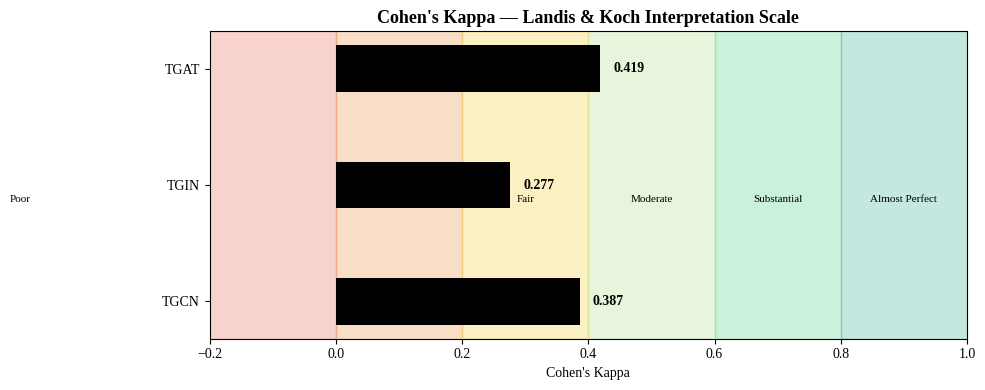

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))

bands = [(-1.0, 0.0, '#e74c3c', 'Poor'), (0.0, 0.20, '#e67e22', 'Slight'),
        (0.20, 0.40, '#f1c40f', 'Fair'), (0.40, 0.60, '#a3d977', 'Moderate'),
        (0.60, 0.80, '#2ecc71', 'Substantial'), (0.80, 1.0, '#16a085', 'Almost Perfect')]

for lo, hi, color, label in bands:
    ax.axvspan(lo, hi, color=color, alpha=0.25)
    ax.text((lo + hi) / 2, 0.85, label, ha='center', fontsize=8, rotation=0)

y_pos = np.arange(len(MODEL_NAMES))
kappa_vals = extended_df["Cohen's Kappa"].values
ax.barh(y_pos, kappa_vals, height=0.4, color='black', zorder=3)
ax.set_yticks(y_pos)
ax.set_yticklabels(MODEL_NAMES)
ax.set_xlim(-0.2, 1.0)
ax.set_xlabel("Cohen's Kappa")
ax.set_title("Cohen's Kappa — Landis & Koch Interpretation Scale", fontsize=13, fontweight='bold')

for i, v in enumerate(kappa_vals):
    ax.text(v + 0.02, i, f'{v:.3f}', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(str(FIG_DIR / 'kappa_interpretation.png'), dpi=130, bbox_inches='tight')
plt.show()

# F2 score — precision-recall plane

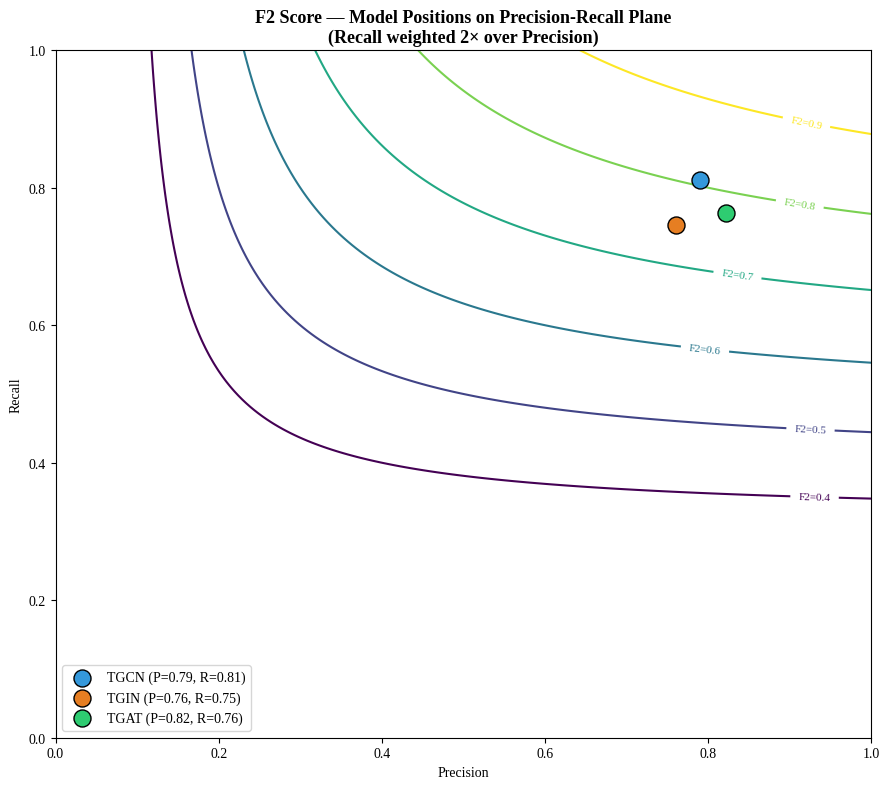

In [ ]:
from sklearn.metrics import precision_score, recall_score

fig, ax = plt.subplots(figsize=(9, 8))

p_grid = np.linspace(0.01, 1, 200)
r_grid = np.linspace(0.01, 1, 200)
P, R = np.meshgrid(p_grid, r_grid)
beta = 2
F2_grid = (1 + beta**2) * (P * R) / ((beta**2 * P) + R + 1e-12)

contour = ax.contour(P, R, F2_grid, levels=[0.4, 0.5, 0.6, 0.7, 0.8, 0.9], cmap='viridis')
ax.clabel(contour, inline=True, fontsize=8, fmt='F2=%.1f')

for model_name in MODEL_NAMES:
    r = results[model_name]
    prec = precision_score(r['labels'], r['preds'], zero_division=0)
    rec  = recall_score(r['labels'], r['preds'], zero_division=0)
    ax.scatter(prec, rec, s=150, color=colors[model_name], edgecolor='black',
              zorder=5, label=f'{model_name} (P={prec:.2f}, R={rec:.2f})')

ax.set_xlabel('Precision'); ax.set_ylabel('Recall')
ax.set_title('F2 Score — Model Positions on Precision-Recall Plane\n(Recall weighted 2× over Precision)',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower left')
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(str(FIG_DIR / 'f2_iso_contours.png'), dpi=130, bbox_inches='tight')
plt.show()

# McNemar's test — contingency matrices

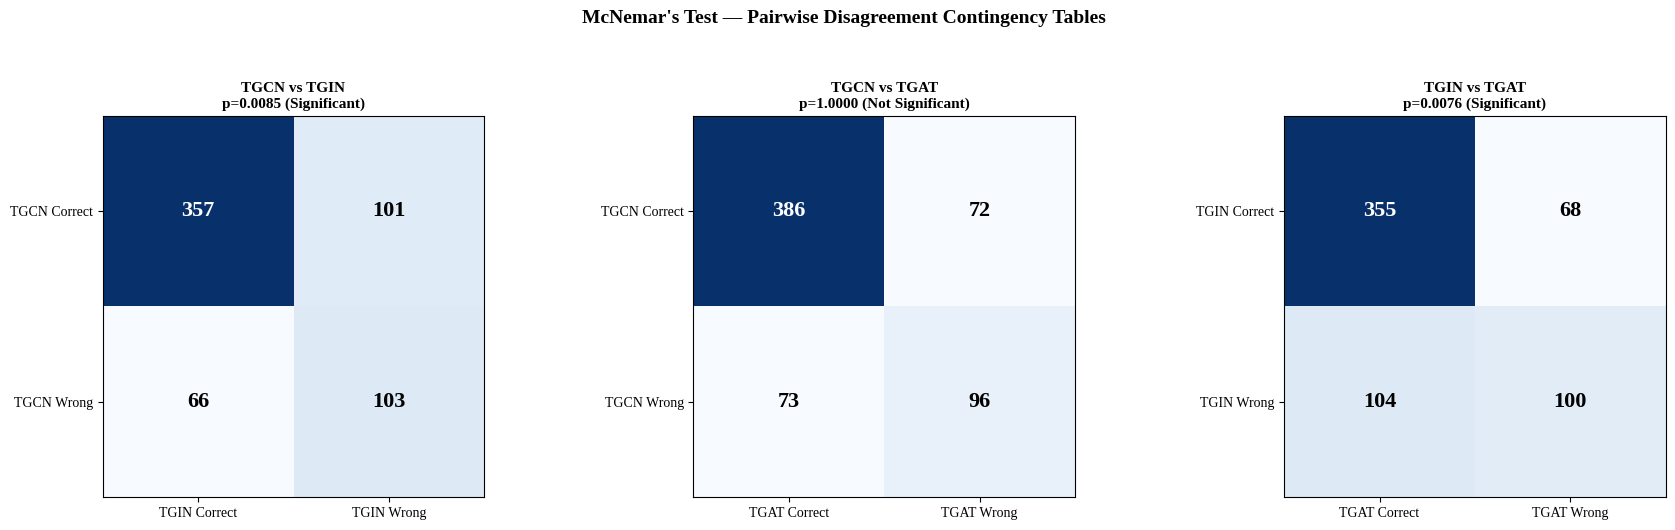

In [ ]:
from itertools import combinations

pairs = list(combinations(MODEL_NAMES, 2))
fig, axes = plt.subplots(1, len(pairs), figsize=(6 * len(pairs), 5))

for idx, (model_a, model_b) in enumerate(pairs):
    preds_a = results[model_a]['preds']
    preds_b = results[model_b]['preds']
    labels  = results[model_a]['labels']

    correct_a = (preds_a == labels)
    correct_b = (preds_b == labels)

    table = np.array([
        [np.sum(correct_a & correct_b),  np.sum(correct_a & ~correct_b)],
        [np.sum(~correct_a & correct_b), np.sum(~correct_a & ~correct_b)]
    ])

    row = mcnemar_df[(mcnemar_df['Model A'] == model_a) & (mcnemar_df['Model B'] == model_b)].iloc[0]
    p_val = row['p-value']
    sig = 'Significant' if p_val < 0.05 else 'Not Significant'

    ax = axes[idx] if len(pairs) > 1 else axes
    im = ax.imshow(table, cmap='Blues')
    ax.set_xticks([0, 1]); ax.set_xticklabels([f'{model_b} Correct', f'{model_b} Wrong'])
    ax.set_yticks([0, 1]); ax.set_yticklabels([f'{model_a} Correct', f'{model_a} Wrong'])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(table[i, j]), ha='center', va='center',
                    fontsize=16, fontweight='bold',
                    color='white' if table[i, j] > table.max()/2 else 'black')
    ax.set_title(f'{model_a} vs {model_b}\np={p_val:.4f} ({sig})', fontsize=11, fontweight='bold')

plt.suptitle("McNemar's Test — Pairwise Disagreement Contingency Tables",
            fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.savefig(str(FIG_DIR / 'mcnemar_contingency.png'), dpi=130, bbox_inches='tight')
plt.show()